# 6. Sturm-Liouville theory: Eigenfunction series expansions

**Pin number**: 

In [13]:
# Define here variables PIN, C_1, C_2, a, b, N, Delta_x and assign appropriate values to them

PIN = 239

C1 = 1 + (PIN/40)
C2 = 4 - (PIN/100)
a = 0
b = 1
N = 128
Delta_x = (b-a)/N

import math
import numpy as np
import matplotlib.pyplot as plt


**Question 1.** Equation (6.15) from the course manual reads in Sturm-Liouville form: 

$ \frac{d}{dx}\left(x^2 \frac{dy}{dx}\right) = -x^2 \lambda y $

**Question 2.**  Define a function yk(k,x) that calculates $y_k(x)$ for different $k$. Plot $y_0(x)$, $y_{10}(x)$, $y_{20}(x)$, $y_{40}(x)$ for $0\leq x \leq 1$. Provide appropriate axis labels and plot title as well as create an appropriate legend. Comment briefly on how $y_k(x)$ changes as $k$ increases. 

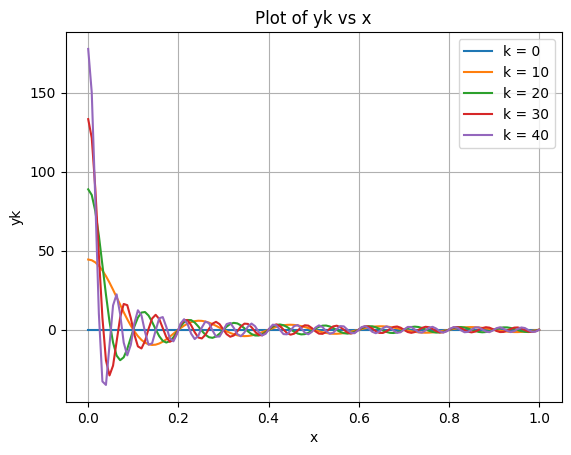

In [14]:
# Use this cell to define yk(k,x) and to plot yk(0,x), yk(10,x), yk(20,x), yk(40,x)

def yk(k,x):
    if x != 0:
        value = math.sqrt(2) * math.sin(k * math.pi * x)
        value = value / x
    else:
        value = math.sqrt(2) * math.pi * k
    return value

for k in range(0, 41, 10):
    x = np.linspace(0, 1, 128)
    y = [yk(k, xi) for xi in x]
    plt.plot(x, y, label=f"k = {k}")

plt.legend()
plt.grid()
plt.xlabel("x")
plt.ylabel("yk")
plt.title("Plot of yk vs x")
plt.show()


Comments on the behaviour of $y_k(x)$ as $k$ increases:

As $k$ increases, the frequency of oscillations of $y_k(x)$ increases, and all of the peaks including the one at x = 0 become taller

**Question 3.**

Coefficients $c_k$ of the eigenfunction series exapansion for $f_1$ are:

$
c_k = C_1 \, \sqrt{2} \, \big( 1 - (-1)^k \big) \left( \frac{1}{(k \pi)^2} + \frac{3}{(k \pi)^3} \right), \quad k \ge 1
$

When k = 0, c_k = 0


Coefficients $\tilde{c}_k$ of the eigenfunction series exapansion for $f_2$ are: 

$
c_k^{(2)} = C_1 \sqrt{2} \, (1 - (-1)^k) \left( \frac{1}{(k \pi)^2} + \frac{3}{(k \pi)^3} \right) + \frac{2 C_2 \sqrt{2} (-1)^{k+1}}{(k \pi)^3}, \quad k \ge 1
$

When k = 0, c_k2 = 0

**Question 4.**  Create a plot showing $f_1(x)$ as well as the corresponding truncated series expansion $S_{40}=\sum_{k=0}^{40}c_k y_k$ for $0\leq x \leq 1$. In a separate figure, plot the absolute error $|f_1(x)-S_{40}(x)|$, restricting it to the range $x_1\leq x\leq 1$.

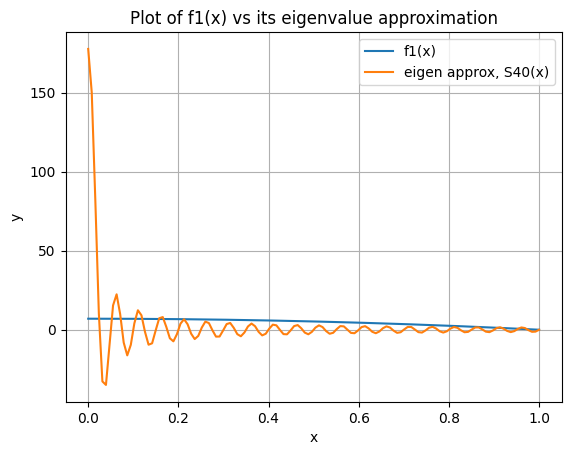

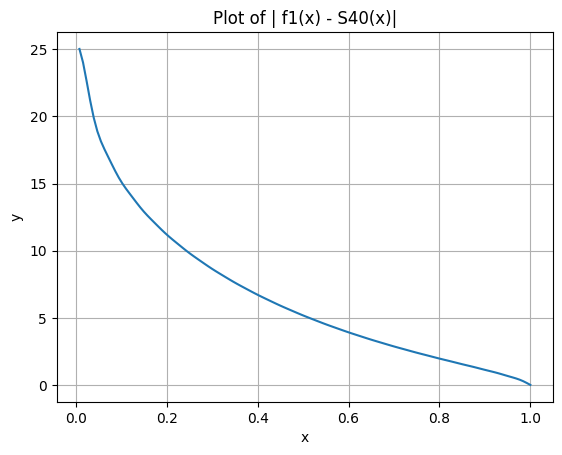

In [15]:
# Use this cell to create a plot for f1(x), the corresponding truncated series expansion S40(x) as well as |f1(x)-S40(x)|

def f1(x):
    value = C1 * (1 - x**2)
    return value

x = np.linspace(0, 1, 128)
y = [f1(xi) for xi in x]
plt.plot(x, y, label="f1(x)")

def ck(k):
    if k == 0:
        return 0
    val1 = C1 * math.sqrt(2) * (1 - (-1)**k)
    val2 = (1/(k * math.pi)**2) + (3/(k * math.pi)**3)
    return val1 * val2

S40 = np.zeros(128)
for k in range(0, 41):
    yk_values = [yk(k, xi) for xi in x]
    S40 += ck(k) * np.array(yk_values)
plt.plot(x, yk_values, label="eigen approx, S40(x)")

plt.xlabel("x")
plt.ylabel("y")
plt.grid()
plt.title("Plot of f1(x) vs its eigenvalue approximation")
plt.legend()
plt.show()

x1 = 1 / 128
mask = x > x1
error = np.abs(y - S40)
plt.plot(x[mask], error[mask])

plt.xlabel("x")
plt.ylabel("y")
plt.grid()
plt.title("Plot of | f1(x) - S40(x)|")
plt.show()



Brief comments on the error $|f_1(x)-S_{40}(x)|$:

$|f_1(x)-S_{40}(x)|$ decreases as x increases. It decreases as a faster rate near x=0 compared with near x=1

**Question 5.** Repeat Question 4 for $f_2(x)$ and its truncated series expansion $T_{40}=\sum_{k=0}^{40}\tilde{c}_k$.

/var/folders/dj/901mwm8s23x_zlv1zxqm8yd80000gn/T/ipykernel_10726/428180546.py:4: RuntimeWarning: divide by zero encountered in scalar divide
  value = C1 * (1 - x**2) + (C2 / x)


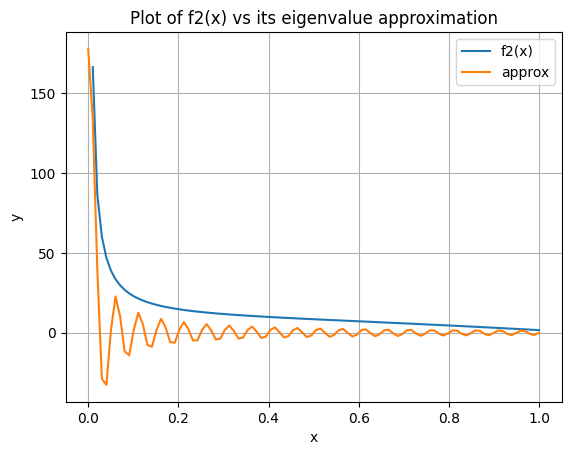

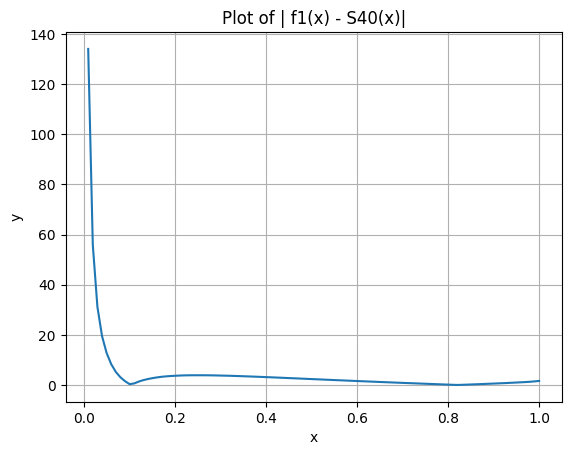

In [9]:
# Use this cell to create a plot for f2(x), the corresponding truncated series expansion T40(x) as well as |f2(x)-T40(x)|

def f2(x):
    value = C1 * (1 - x**2) + (C2 / x)
    return value

x = np.linspace(0, 1, 100)
y = [f2(xi) for xi in x]
plt.plot(x, y, label="f2(x)")

def ck2(k):
    if k == 0:
        return 0
    val = (C2 * math.sqrt(2) * 2 * (-1)**(k+1))/(k * math.pi)**3
    return ck(k) + val

S40 = np.zeros(100)
for k in range(0, 41):
    yk_values = [yk(k, xi) for xi in x]
    S40 += ck2(k) * np.array(yk_values)
plt.plot(x, yk_values, label="approx")

plt.xlabel("x")
plt.ylabel("y")
plt.grid()
plt.title("Plot of f2(x) vs its eigenvalue approximation")
plt.legend()
plt.show()

x1 = 1 / 128
mask = x > x1
error = np.abs(y - S40)
plt.plot(x[mask], error[mask])

plt.xlabel("x")
plt.ylabel("y")
plt.grid()
plt.title("Plot of | f1(x) - S40(x)|")
plt.show()





Brief comments on the error $|f_2(x)-T_{40}(x)|$ and comparison to $|f_1(x)-S_{40}(x)|$:

The error drops off massively near x = 0, much faster than $|f_1(x)-S_{40}(x)|$ untill it reaches a minimum as approximatly x = 0.55

**Question 6.** Create two plots showing $|f_1(x)-S_{20}(x)|$, $|f_1(x)-S_{40}(x)|$, and $|f_1(x)-S_{80}(x)|$: one for the range $x_0\leq x\leq 1$ and one for the range $x_1\leq x\leq 1$.

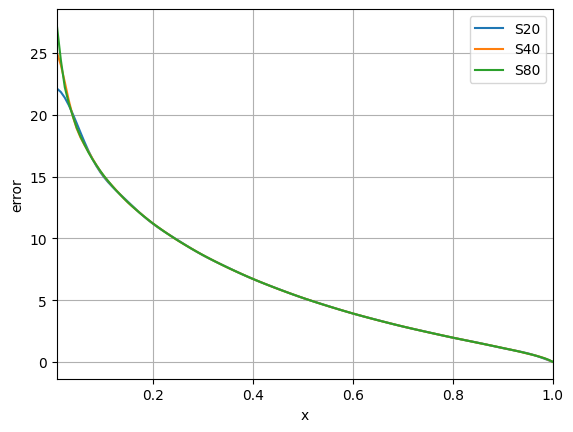

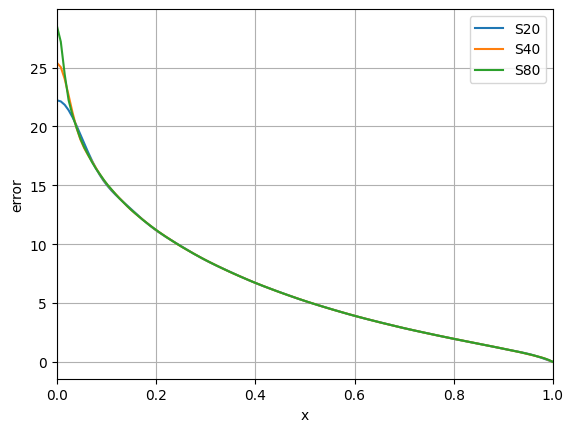

In [ ]:
# Use this cell to plot |f1(x)-S20(x)|, |f1(x)-S40(x)|, |f1(x)-S80(x)| for the ranges specified in the manual

x = np.linspace(0, 1, 128)
y = [f1(xi) for xi in x]

x1 = 1 / 128
mask = x > x1

S20 = np.zeros(128)
for k in range(0, 21):
    yk_values = [yk(k, xi) for xi in x]
    S20 += ck(k) * np.array(yk_values)

error1 = np.abs(y - S20)
plt.plot(x[mask], error1[mask], label="S20")

S40 = np.zeros(128)
for k in range(0, 41):
    yk_values = [yk(k, xi) for xi in x]
    S40 += ck(k) * np.array(yk_values)

error2 = np.abs(y - S40)
plt.plot(x[mask], error2[mask], label="S40")

S80 = np.zeros(128)
for k in range(0, 81):
    yk_values = [yk(k, xi) for xi in x]
    S80 += ck(k) * np.array(yk_values)

error3 = np.abs(y - S80)
plt.plot(x[mask], error3[mask], label="S80")

plt.xlabel("x")
plt.ylabel("error")
plt.title("error vs x for f1(x)")
plt.grid()
plt.legend()
plt.xlim(x1, 1)
plt.show()

plt.plot(x, error1, label="S20")
plt.plot(x, error2, label="S40")
plt.plot(x, error3, label="S80")

plt.xlabel("x")
plt.ylabel("error")
plt.title("error vs x for f1(x)")
plt.grid()
plt.legend()
plt.xlim(0, 1)
plt.show()



Comments on error behaviour as the number of eigenfunctions in the truncated series increases:

Initially near x=0, the higher the sum range, the higher the error, untill about x = 0.3 where they all converge into the same error vs x curve

**Question 7.** Create two plots showing $|f_2(x)-T_{20}(x)|$, $|f_2(x)-T_{40}(x)|$, and $|f_2(x)-T_{80}(x)|$: one for the range $x_2\leq x\leq x_{10}$ and one for the range $x_{120}\leq x\leq 1$.

/var/folders/dj/901mwm8s23x_zlv1zxqm8yd80000gn/T/ipykernel_10726/428180546.py:4: RuntimeWarning: divide by zero encountered in scalar divide
  value = C1 * (1 - x**2) + (C2 / x)


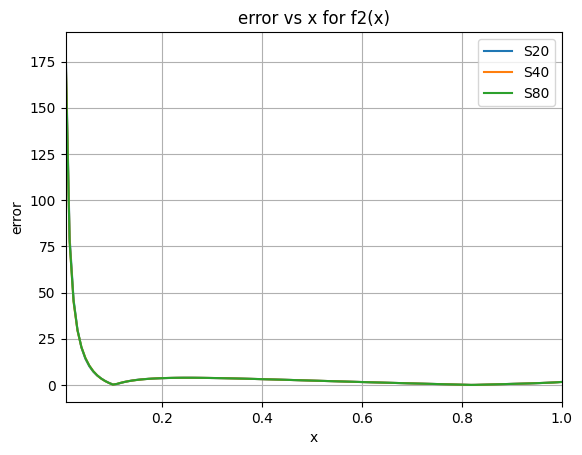

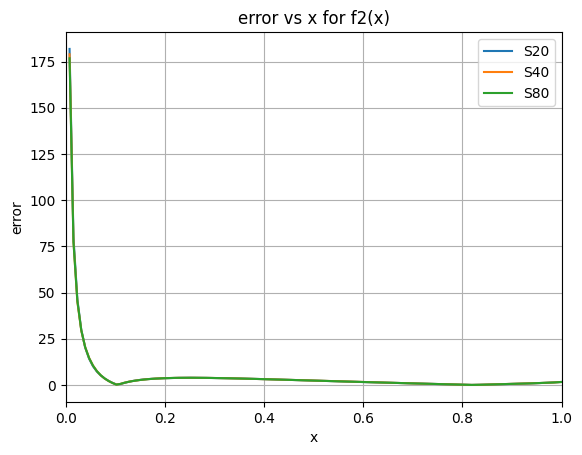

In [16]:
# Use this cell to plot |f2(x)-T20(x)|, |f2(x)-T40(x)|, |f2(x)-T80(x)| for the ranges specified in the manual

x = np.linspace(0, 1, 128)
y = [f2(xi) for xi in x]

x1 = 1 / 128
mask = x > x1

S20 = np.zeros(128)
for k in range(0, 21):
    yk_values = [yk(k, xi) for xi in x]
    S20 += ck2(k) * np.array(yk_values)

error1 = np.abs(y - S20)
plt.plot(x[mask], error1[mask], label="S20")

S40 = np.zeros(128)
for k in range(0, 41):
    yk_values = [yk(k, xi) for xi in x]
    S40 += ck2(k) * np.array(yk_values)

error2 = np.abs(y - S40)
plt.plot(x[mask], error2[mask], label="S40")

S80 = np.zeros(128)
for k in range(0, 81):
    yk_values = [yk(k, xi) for xi in x]
    S80 += ck2(k) * np.array(yk_values)

error3 = np.abs(y - S80)
plt.plot(x[mask], error3[mask], label="S80")

plt.xlabel("x")
plt.ylabel("error")
plt.title("error vs x for f2(x)")
plt.grid()
plt.legend()
plt.xlim(x1, 1)
plt.show()

plt.plot(x, error1, label="S20")
plt.plot(x, error2, label="S40")
plt.plot(x, error3, label="S80")

plt.xlabel("x")
plt.ylabel("error")
plt.title("error vs x for f2(x)")
plt.grid()
plt.legend()
plt.xlim(0, 1)
plt.show()



Comments on error behaviour as the number of eigenfunctions in the truncated series increases:

All sum ranges give the same error vs x curve

The error near x=0 is much larger than that of f1(x)

**Question 8.** Comments on the expected error behaviour of the eigenfunctions expansion for $f_3(x)$ and $f_4(x)$ as defined in the manual:

for f3(x) both Boundary Conditions match, so errors near x=0 and x=1 will be relatively low. Additionally the error will decay quick

for f4(x) the boundary condition at x=1 isn't a match, so slower convergence near boundaries